# TRABAJO BIG DATA

In [596]:
# importamos paquetes
import os
import numpy as np
import pandas as pd
import statistics
import matplotlib.pyplot as plt
import seaborn as sns
import powerlaw
from datetime import datetime
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, roc_auc_score, RocCurveDisplay, mean_squared_error, precision_score, recall_score, f1_score
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

In [598]:
# directorio
# ruta absoluta del original, no portable:
# os.chdir('/Users/catalinagallardo/Downloads/University/Big Data/E337-Grupo5')

In [600]:
# importamos bases de datos 
df_2018 = pd.read_csv('base_2018.csv', low_memory=False)
df_2019 = pd.read_csv('base_2019.csv', low_memory=False)
df = pd.merge(df_2018[['track_id', 'popularity_2018']], df_2019[['track_id', 'popularity_2019']], on='track_id')

## Estadística Descriptiva

### Tabla 2018 vs 2019

In [603]:
# calculamos estadisticos
count = [df_2018['popularity_2018'].count(), df_2019['popularity_2019'].count()]
mean = [df_2018['popularity_2018'].mean(), df_2019['popularity_2019'].mean()]
std = [np.std(df_2018['popularity_2018']), np.std(df_2019['popularity_2019'])]

In [604]:
# armamos tabla
statistics = pd.DataFrame({'': [2018, 2019], 'n': count, 'X': mean, 'Standard Deviation': std})

In [608]:
# exportamos a LaTeX
statistics = statistics.round(2)
statistics = statistics.to_latex(index=False, caption="Tabla de Estadísticas Descriptivas (2018 vs 2019)", label="tab:stats", float_format="%.2f")

with open("estadistica-descriptiva.tex", "w") as f:
    f.write(statistics)

### Top 3

In [611]:
# encontramos el top 3 de canciones en la base 2018 y en 2019
ranking_2018 = df_2018.sort_values(by='popularity_2018', ascending=False).head(3)
ranking_2019 = df_2019.sort_values(by='popularity_2019', ascending=False).head(3)

In [612]:
# acomodamos datos 2018
songs_2018 = list(ranking_2018['track_name'].head(3))
artists_2018 = list(ranking_2018['artist_name'].head(3))
top_2018 = []

for song, artist in zip(songs_2018, artists_2018):
    top_2018.append(f'{song} by {artist}')

In [615]:
# acomodamos datos 2019
songs_2019 = list(ranking_2019['track_name'].head(3))
artists_2019 = list(ranking_2019['artist_name'].head(3))
top_2019 = []

for song, artist in zip(songs_2019, artists_2019):
    top_2019.append(f'{song} by {artist}')

In [617]:
# armamos tabla
top_3 = pd.DataFrame({2018: top_2018, 2019: top_2019})

In [619]:
# exportamos a LaTeX
top_3 = top_3.to_latex(index=False, caption="Tabla de Top 3 Canciones (2018 vs 2019)", label="tab:top", float_format="%.2f")

with open("top-canciones.tex", "w") as f:
    f.write(top_3)

## Graficamos

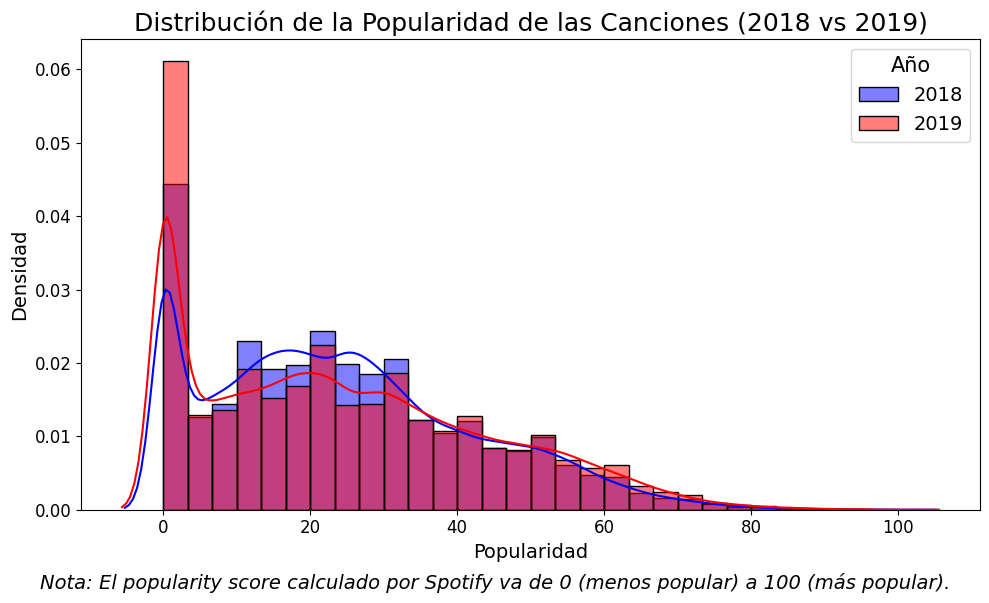

In [622]:
# hacemos histograma para comparar distribución 2018 y 2019 
min_val = min(df_2018['popularity_2018'].min(), df_2019['popularity_2019'].min())
max_val = max(df_2018['popularity_2018'].max(), df_2019['popularity_2019'].max())
bins = np.linspace(min_val, max_val, 31)

plt.figure(figsize=(10, 6))

sns.histplot(df_2018['popularity_2018'], bins=bins, color='blue', alpha=0.5, label='2018', stat='density')
sns.histplot(df_2019['popularity_2019'], bins=bins, color='red', alpha=0.5, label='2019', stat='density')

sns.kdeplot(df_2018['popularity_2018'], color='blue', bw_adjust=1)
sns.kdeplot(df_2019['popularity_2019'], color='red', bw_adjust=1)

plt.title('Distribución de la Popularidad de las Canciones (2018 vs 2019)', fontsize=18)
plt.xlabel('Popularidad', fontsize=14)
plt.ylabel('Densidad', fontsize=14)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.legend(title='Año', title_fontsize=15, fontsize=14)

plt.figtext(0.5, 0.01, 'Nota: El popularity score calculado por Spotify va de 0 (menos popular) a 100 (más popular).',
            wrap=True, horizontalalignment='center', fontsize=14, style='italic')

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("popularidad.png", dpi=300)
plt.show()

## Modelamos

In [625]:
# preparamos dummy del top 1% del 2018 y 2019
threshold_2018 = np.percentile(df_2018['popularity_2018'], 99)
df_2018['y_2018'] = (df_2018['popularity_2018'] >= threshold_2018).astype(int)
y_2018 = df_2018['y_2018'].to_numpy()

threshold_2019 = np.percentile(df_2019['popularity_2019'], 99)
df_2019['y_2019'] = (df_2019['popularity_2019'] >= threshold_2019).astype(int)
y_2019 = df_2019['y_2019'].to_numpy()

### Estimador de Máxima Verosimilitud

In [628]:
# usamos base 2018 para entrenar el modelo
data = df_2018['popularity_2018'].to_numpy()

In [630]:
# definimos función para calcular probabilidad
def powerlaw_prob(x):
    if x < xmin:
        return 0
    return (x / threshold_2018) ** - (alpha + 1)

In [632]:
# modelamos
results = powerlaw.Fit(data, discrete=True)
alpha = results.power_law.alpha
xmin = results.power_law.xmin
print(f'El alpha es {alpha} y el xmin es {xmin}.')

Calculating best minimal value for power law fit
El alpha es 8.706378444978457 y el xmin es 56.0.


Values less than or equal to 0 in data. Throwing out 0 or negative values


In [634]:
# testeamos usando base 2019, calculamos probabilidad y predecimos usando clasificador de Bayes
y_probPL = df_2019['popularity_2019'].apply(powerlaw_prob).to_numpy()
y_predPL = (y_probPL >= 0.5).astype(int)

In [636]:
# calculamos medidas de precisión
matriz_confusionPL = confusion_matrix(y_2019, y_predPL)
accuracyPL = accuracy_score(y_2019, y_predPL)
precisionPL = precision_score(y_2019, y_predPL)
recallPL = recall_score(y_2019, y_predPL)
f1PL = f1_score(y_2019, y_predPL)
aucPL = roc_auc_score(y_2019, y_probPL)
msePL = mean_squared_error(y_2019, y_predPL)
fprPL, tprPL, thresholdsPL = roc_curve(y_2019, y_probPL, drop_intermediate=False)

In [638]:
# imprimimos resultados
print(f'La matriz de confusión es: \n {matriz_confusionPL}')
print(f'El accuracy score es: {accuracyPL}.')
print(f'La precisión es: {precisionPL}.')
print(f'El recall es: {recallPL}.')
print(f'El F1-score es: {f1PL}.')
print(f'El área bajo la curva ROC es: {aucPL}.')
print(f'El error cuadrático medio de la muestra de testeo es: {msePL}.')

La matriz de confusión es: 
 [[119026   8916]
 [   841    653]]
El accuracy score es: 0.9246191167835842.
La precisión es: 0.06824119552722333.
El recall es: 0.43708165997322623.
El F1-score es: 0.1180511615294224.
El área bajo la curva ROC es: 0.9303121727032562.
El error cuadrático medio de la muestra de testeo es: 0.07538088321641584.


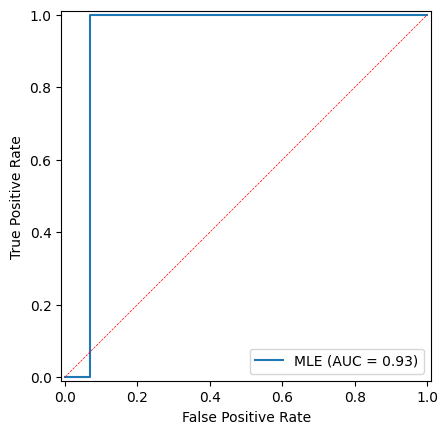

In [640]:
# graficamos
displayPL = RocCurveDisplay(fpr=fprPL, tpr=tprPL, roc_auc=aucPL, estimator_name='MLE')
displayPL.plot()
plt.plot([0, 1], [0, 1], color='red', linestyle='--', linewidth=0.5)
plt.savefig("power-law.png", dpi=300, bbox_inches='tight')
plt.show()

### Random Forest Regressor

In [53]:
# predictores que usaremos
predictors = ['acousticness', 'danceability', 'duration_ms', 'energy', 'instrumentalness', 'key', 'liveness', 'loudness',
              'mode', 'speechiness', 'tempo', 'time_signature', 'valence', 'artist_count', 'explicit_dummy', 'song_age']

In [55]:
# usamos la base 2018 de entrenamiento y la base 2019 de testeo 
X_train = df_2018[predictors]
y_train = df_2018['y_2018']

X_test = df_2019[predictors]
y_test = df_2019['y_2019']

In [61]:
# usamos cross-validation para elegir los hiperparámetros
parametros = {'bootstrap': [True], 'max_samples': [0.25, 0.5, 0.75], 
              'max_features': [3, 6, 9, "sqrt", None], 'n_estimators': [25, 50, 75, 100]}

cv = KFold(n_splits=10, random_state=444, shuffle=True)
modelo = RandomForestClassifier(random_state=444)

grid = GridSearchCV(estimator=modelo, param_grid=parametros, cv=cv, verbose=1, n_jobs=-1)
grid.fit(X_train, y_train)

RF = grid.best_estimator_
print("Mejores parámetros encontrados:", grid.best_params_)

Fitting 10 folds for each of 60 candidates, totalling 600 fits
Mejores parámetros encontrados: {'bootstrap': True, 'max_features': 3, 'max_samples': 0.75, 'n_estimators': 25}


In [62]:
# modelamos, calculamos probabilidad
RF.fit(X_train, y_train)
df_2019['y_probRF'] = RF.predict_proba(X_test)[:, 1]
y_probRF = df_2019['y_probRF'].to_numpy()

In [63]:
# creamos dummy de predicción usando clasificador de bayes
df_2019['y_predRF'] = (df_2019['y_probRF'] >= 0.5).astype(int)
y_predRF = df_2019['y_predRF'].to_numpy()

In [64]:
# calculamos medidas de precisión
matriz_confusionRF = confusion_matrix(y_2019, y_predRF)
accuracyRF = accuracy_score(y_2019, y_predRF)
precisionRF = precision_score(y_2019, y_predRF)
recallRF = recall_score(y_2019, y_predRF)
f1RF = f1_score(y_2019, y_predRF)
aucRF = roc_auc_score(y_2019, y_probRF)
mseRF = mean_squared_error(y_2019, y_predRF)
fprRF, tprRF, thresholdsRF = roc_curve(y_2019, y_probRF, drop_intermediate=False)

In [65]:
# imprimimos resultados
print(f'La matriz de confusión es: \n {matriz_confusionRF}')
print(f'El accuracy score es: {accuracyRF}.')
print(f'La precisión es: {precisionRF}.')
print(f'El recall es: {recallRF}.')
print(f'El F1-score es: {f1RF}.')
print(f'El área bajo la curva ROC es: {aucRF}')
print(f'El error cuadrático medio de la muestra de testeo es: {mseRF}')

La matriz de confusión es: 
 [[127634    308]
 [   974    520]]
El accuracy score es: 0.9900954912080101.
La precisión es: 0.6280193236714976.
El recall es: 0.34805890227576974.
El F1-score es: 0.4478897502153316.
El área bajo la curva ROC es: 0.8438652584942846
El error cuadrático medio de la muestra de testeo es: 0.009904508791989864


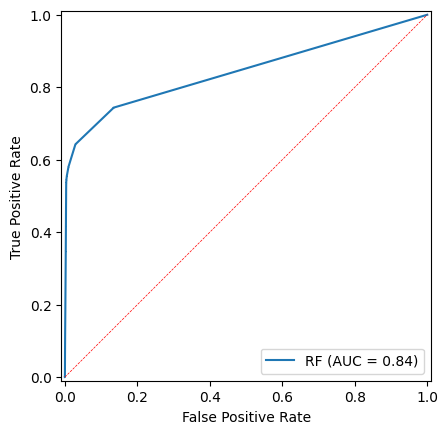

In [66]:
# graficamos su curva ROC
displayRF = RocCurveDisplay(fpr=fprRF, tpr=tprRF, roc_auc=aucRF, estimator_name='RF')
displayRF.plot()
plt.plot([0, 1], [0, 1], color='red', linestyle='--', linewidth=.5)
plt.savefig("random-forest.png", dpi=300, bbox_inches='tight')
plt.show()

## Guardamos Resultados

In [642]:
# creamos tabla de resultados y exportamos a LaTeX
resultados = {"Estimador": ["Power Law", "Random Forest"], "Accuracy": [accuracyPL, accuracyRF],
             "Precision": [precisionPL, precisionRF], "Recall": [recallPL, recallRF], "F1 Score": [f1PL, f1RF],
              "AUC": [aucPL, aucRF], "MSE": [msePL, mseRF]}

resultados = pd.DataFrame(resultados)
tabla_latex = resultados.set_index("Estimador").to_latex(float_format="%.3f")

with open('resultados.tex', 'w', encoding='utf-8') as f:
    f.write(tabla_latex)

In [644]:
# imprimimos matrices para LaTeX
matrices = ['matriz_confusionPL', 'matriz_confusionRF']

for matriz in matrices:
    data = globals()[matriz]
    cm_df = pd.DataFrame(data, index=["Real 0", "Real 1"], columns=["Pred 0", "Pred 1"])
    print(f"% {matriz}")
    print(cm_df.to_latex())

% matriz_confusionPL
\begin{tabular}{lrr}
\toprule
 & Pred 0 & Pred 1 \\
\midrule
Real 0 & 119026 & 8916 \\
Real 1 & 841 & 653 \\
\bottomrule
\end{tabular}

% matriz_confusionRF
\begin{tabular}{lrr}
\toprule
 & Pred 0 & Pred 1 \\
\midrule
Real 0 & 127634 & 308 \\
Real 1 & 974 & 520 \\
\bottomrule
\end{tabular}



FIN :)